**Installing dependencies**

In [1]:
%pip install -q rdkit pandas numpy matplotlib seaborn scikit-learn

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

sns.set_theme(style="whitegrid")

RAW_PATH = Path("/content/tox21.csv")


df = pd.read_csv(RAW_PATH)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (7831, 14)

First five rows:


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O



Data types:
NR-AR            float64
NR-AR-LBD        float64
NR-AhR           float64
NR-Aromatase     float64
NR-ER            float64
NR-ER-LBD        float64
NR-PPAR-gamma    float64
SR-ARE           float64
SR-ATAD5         float64
SR-HSE           float64
SR-MMP           float64
SR-p53           float64
mol_id            object
smiles            object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7831 entries, 0 to 7830
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   NR-AR          7265 non-null   float64
 1   NR-AR-LBD      6758 non-null   float64
 2   NR-AhR         6549 non-null   float64
 3   NR-Aromatase   5821 non-null   float64
 4   NR-ER          6193 non-null   float64
 5   NR-ER-LBD      6955 non-null   float64
 6   NR-PPAR-gamma  6450 non-null   float64
 7   SR-ARE         5832 non-null   float64
 8   SR-ATAD5       7072 non-null   float64
 9   SR-HS

**Missing Values**

In [7]:
ENDPOINTS = [
    "NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase",
    "NR-ER", "NR-ER-LBD", "NR-PPAR-gamma",
    "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"
]

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing)

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate molecule IDs:", df["mol_id"].duplicated().sum())

print("\nUnexpected target labels:")
for col in ENDPOINTS:
    values = set(df[col].dropna().unique())
    unexpected = values - {0, 1}
    if unexpected:
        print(col, unexpected)

,missing_count,missing_percent
SR-MMP,2021,25.81
NR-Aromatase,2010,25.67
SR-ARE,1999,25.53
NR-ER,1638,20.92
NR-PPAR-gamma,1381,17.64
SR-HSE,1364,17.42
NR-AhR,1282,16.37
NR-AR-LBD,1073,13.70
SR-p53,1057,13.50
NR-ER-LBD,876,11.19


Exact duplicate rows: 0
Duplicate molecule IDs: 0

Unexpected target labels:


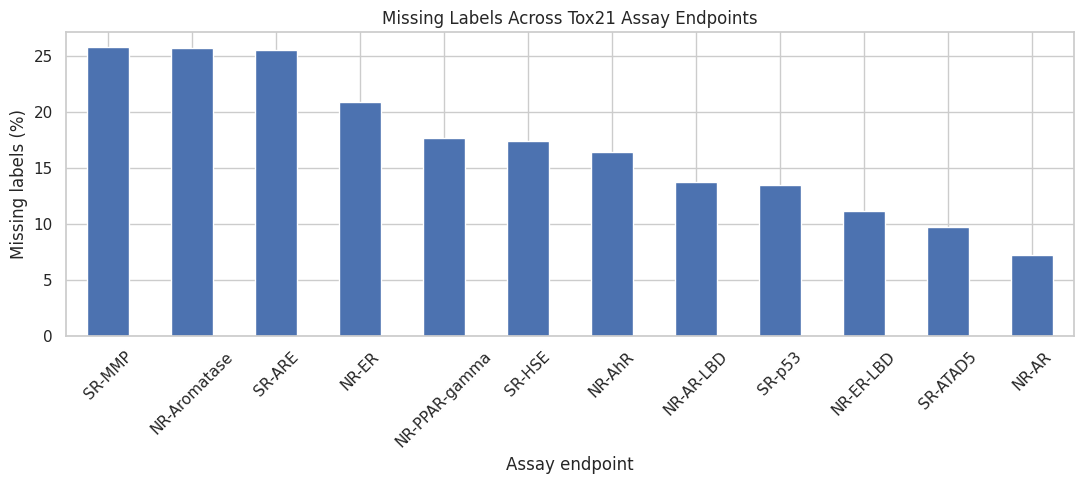

In [8]:
#Missing labels bar chart
ENDPOINTS = [
    "NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase",
    "NR-ER", "NR-ER-LBD", "NR-PPAR-gamma",
    "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"
]

missing_pct = df[ENDPOINTS].isna().mean().mul(100)
missing_pct = missing_pct.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))

missing_pct.plot(kind="bar", ax=ax)

ax.set_title("Missing Labels Across Tox21 Assay Endpoints")
ax.set_xlabel("Assay endpoint")
ax.set_ylabel("Missing labels (%)")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

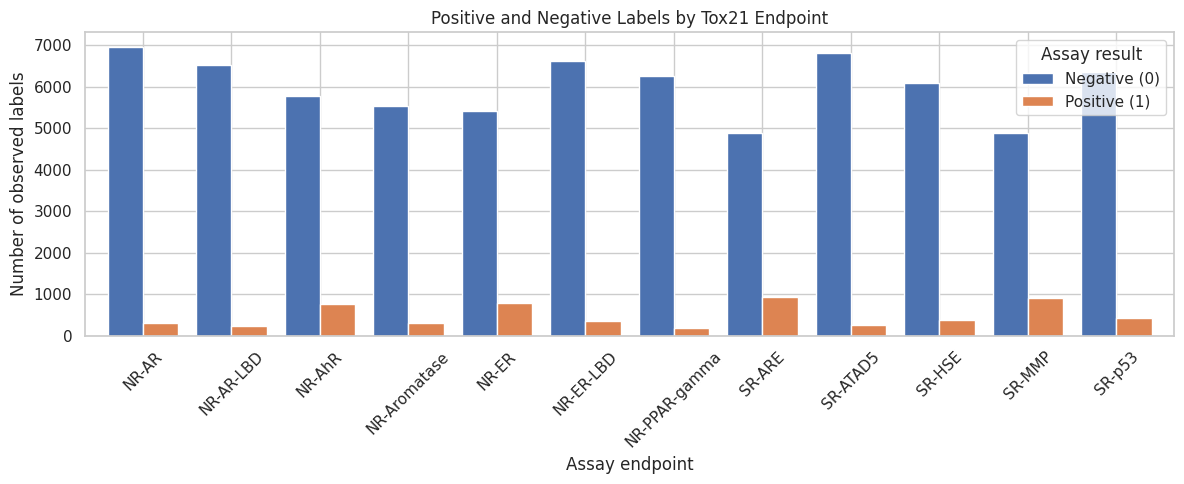

In [9]:
#positive vs negative labels
positive_counts = df[ENDPOINTS].eq(1).sum()
negative_counts = df[ENDPOINTS].eq(0).sum()

counts = pd.DataFrame({
    "Negative (0)": negative_counts,
    "Positive (1)": positive_counts
})

ax = counts.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

ax.set_title("Positive and Negative Labels by Tox21 Endpoint")
ax.set_xlabel("Assay endpoint")
ax.set_ylabel("Number of observed labels")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Assay result")

plt.tight_layout()
plt.show()

In [10]:
#positive rate among observed labels only
observed_counts = positive_counts + negative_counts

target_summary = pd.DataFrame({
    "negative": negative_counts,
    "positive": positive_counts,
    "observed": observed_counts,
    "missing": df[ENDPOINTS].isna().sum(),
    "positive_rate_pct": (
        positive_counts / observed_counts * 100
    ).round(2)
})

display(target_summary.sort_values("positive_rate_pct"))

,negative,positive,observed,missing,positive_rate_pct
NR-PPAR-gamma,6264,186,6450,1381,2.88
NR-AR-LBD,6521,237,6758,1073,3.51
SR-ATAD5,6808,264,7072,759,3.73
NR-AR,6956,309,7265,566,4.25
NR-ER-LBD,6605,350,6955,876,5.03
NR-Aromatase,5521,300,5821,2010,5.15
SR-HSE,6095,372,6467,1364,5.75
SR-p53,6351,423,6774,1057,6.24
NR-AhR,5781,768,6549,1282,11.73
NR-ER,5400,793,6193,1638,12.80


In [11]:
majority_baseline = (
    target_summary["negative"] / target_summary["observed"] * 100
).round(2)

target_summary["majority_class_accuracy_pct"] = majority_baseline

display(
    target_summary[
        ["negative", "positive", "observed",
         "positive_rate_pct", "majority_class_accuracy_pct"]
    ].sort_values("positive_rate_pct")
)

#This is not a trained model. It's a sanity-check baseline that demonstrates why accuracy alone is insufficient.



,negative,positive,observed,positive_rate_pct,majority_class_accuracy_pct
NR-PPAR-gamma,6264,186,6450,2.88,97.12
NR-AR-LBD,6521,237,6758,3.51,96.49
SR-ATAD5,6808,264,7072,3.73,96.27
NR-AR,6956,309,7265,4.25,95.75
NR-ER-LBD,6605,350,6955,5.03,94.97
NR-Aromatase,5521,300,5821,5.15,94.85
SR-HSE,6095,372,6467,5.75,94.25
SR-p53,6351,423,6774,6.24,93.76
NR-AhR,5781,768,6549,11.73,88.27
NR-ER,5400,793,6193,12.80,87.20


**Parsing basic molecular properties**

In [12]:
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

# Preserve the raw dataframe.
eda_df = df.copy()

def parse_smiles(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None
    return Chem.MolFromSmiles(smiles)

eda_df["mol"] = eda_df["smiles"].map(parse_smiles)

eda_df["valid_smiles"] = eda_df["mol"].notna()

print("Total molecules:", len(eda_df))
print("Valid SMILES:", eda_df["valid_smiles"].sum())
print("Invalid SMILES:", (~eda_df["valid_smiles"]).sum())
print(
    "Invalid percentage:",
    round((~eda_df["valid_smiles"]).mean() * 100, 3),
    "%"
)

[09:17:24] WARNING: not removing hydrogen atom without neighbors
[09:17:25] Explicit valence for atom # 8 Al, 6, is greater than permitted
[09:17:25] Explicit valence for atom # 3 Al, 6, is greater than permitted
[09:17:25] Explicit valence for atom # 4 Al, 6, is greater than permitted
[09:17:25] Explicit valence for atom # 4 Al, 6, is greater than permitted
[09:17:26] Explicit valence for atom # 9 Al, 6, is greater than permitted
[09:17:26] Explicit valence for atom # 5 Al, 6, is greater than permitted
[09:17:26] Explicit valence for atom # 16 Al, 6, is greater than permitted
[09:17:26] Explicit valence for atom # 20 Al, 6, is greater than permitted


Total molecules: 7831
Valid SMILES: 7823
Invalid SMILES: 8
Invalid percentage: 0.102 %


In [13]:
valid = eda_df.loc[eda_df["valid_smiles"]].copy()

valid["mol_weight"] = valid["mol"].map(Descriptors.MolWt)
valid["heavy_atoms"] = valid["mol"].map(
    lambda mol: mol.GetNumHeavyAtoms()
)
valid["ring_count"] = valid["mol"].map(
    rdMolDescriptors.CalcNumRings
)

display(
    valid[["mol_weight", "heavy_atoms", "ring_count"]].describe()
)

,mol_weight,heavy_atoms,ring_count
count,7823.000000,7823.000000,7823.000000
mean,276.144155,18.566918,1.823597
std,164.732356,11.309542,3.772937
min,9.012000,1.000000,0.000000
25%,165.236000,11.000000,1.000000
50%,240.302000,16.000000,1.000000
75%,343.044000,23.000000,3.000000
max,1877.664000,132.000000,264.000000


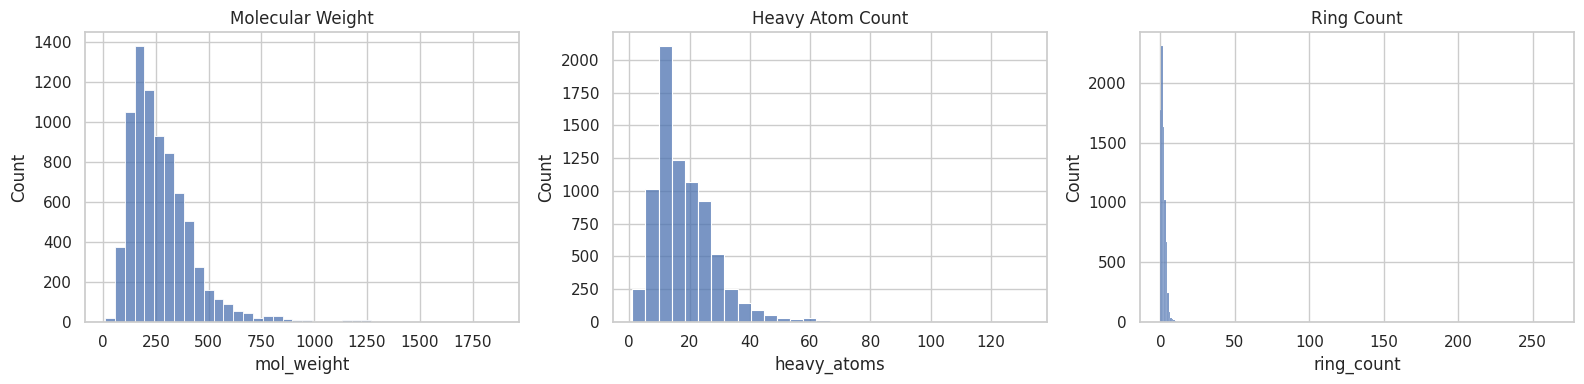

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(valid["mol_weight"], bins=40, ax=axes[0])
axes[0].set_title("Molecular Weight")

sns.histplot(valid["heavy_atoms"], bins=30, ax=axes[1])
axes[1].set_title("Heavy Atom Count")

sns.histplot(valid["ring_count"], discrete=True, ax=axes[2])
axes[2].set_title("Ring Count")

plt.tight_layout()
plt.show()

most molecules are relatively small, but a small number have unusually large molecular weights, many heavy atoms, or exceptionally high ring counts. We should investigate those extremes before deciding whether they're genuine structures or data-quality problems.

In [15]:
# Inspect the most extreme molecules
outliers = valid.nlargest(15, "ring_count")[
    ["mol_id", "smiles", "mol_weight", "heavy_atoms", "ring_count"]
]

display(outliers.to_string(index=False))

'  mol_id                                                                                                                                                                                                                                                                                                                                                 smiles  mol_weight  heavy_atoms  ring_count\nTOX27033                  OC[C@H]1O[C@@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@H]6[C@@H](CO)O[C@H](O[C@@H]7[C@@H](CO)O[C@H](O[C@@H]8[C@@H](CO)O[C@H](O[C@@H]9[C@@H](CO)O[C@H](O[C@H]1[C@H](O)[C@H]2O)[C@H](O)[C@H]9O)[C@H](O)[C@H]8O)[C@H](O)[C@H]7O)[C@H](O)[C@H]6O)[C@H](O)[C@H]5O)[C@H](O)[C@H]4O)[C@H](O)[C@H]3O    1297.128           88         264\n  TOX358                                                           OC[C@H]1O[C@@H]2O[C@@H]3[C@@H](CO)O[C@H](O[C@@H]4[C@@H](CO)O[C@H](O[C@@H]5[C@@H](CO)O[C@H](O[C@@H]6[C@@H](CO)O[C@H](O[C@@H]7[C@@H](CO)O[C@H](O[C@@H]8[C@

In [16]:
display(
    valid.nlargest(15, "mol_weight")[
        ["mol_id", "smiles", "mol_weight", "heavy_atoms", "ring_count"]
    ].to_string(index=False)
)

'  mol_id                                                                                                                                                                                                                                                                                                                                                 smiles  mol_weight  heavy_atoms  ring_count\nTOX26917 CCCCC/C=C\\CCC(=O)N[C@H]1[C@H](Oc2c3cc4cc2Oc2ccc(cc2Cl)[C@@H](O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2NC(C)=O)[C@@H]2NC(=O)[C@H](NC(=O)[C@@H]4NC(=O)[C@H]4NC(=O)[C@@H](Cc5ccc(c(Cl)c5)O3)NC(=O)[C@@H](N)c3ccc(O)c(c3)Oc3cc(O)cc4c3)c3ccc(O)c(c3)-c3c(O[C@H]4O[C@H](CO)[C@@H](O)[C@H](O)[C@@H]4O)cc(O)cc3[C@H](C(=O)O)NC2=O)O[C@H](CO)[C@@H](O)[C@@H]1O    1877.664          132          16\n TOX6076                                                                                O=C(OC[C@H]1O[C@@H](OC(=O)c2cc(O)c(O)c(OC(=O)c3cc(O)c(O)c(O)c3)c2)[C@H](OC(=O)c2cc(O)c(O)c(OC(=O)c3cc(O)c(O)c(O)c3)c2)[C@@H](OC(=O

In [17]:
properties = ["mol_weight", "heavy_atoms", "ring_count"]

for col in properties:
    q1 = valid[col].quantile(0.25)
    q3 = valid[col].quantile(0.75)
    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    flagged = valid[valid[col] > upper]

    print(f"\n{col}")
    print(f"Upper IQR threshold: {upper:.2f}")
    print(f"Flagged molecules: {len(flagged)}")


mol_weight
Upper IQR threshold: 609.76
Flagged molecules: 296

heavy_atoms
Upper IQR threshold: 41.00
Flagged molecules: 283

ring_count
Upper IQR threshold: 6.00
Flagged molecules: 95


In [18]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()

def canonicalize_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    mol = chooser.choose(mol)
    return Chem.MolToSmiles(mol, canonical=True)

eda_df["canonical_smiles"] = eda_df["smiles"].map(
    canonicalize_smiles
)

print("Invalid after standardization:",
      eda_df["canonical_smiles"].isna().sum())

print("Duplicate canonical structures:",
      eda_df["canonical_smiles"].duplicated().sum())

Streaming output truncated to the last 5000 lines.
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running LargestFragmentChooser
[09:25:20] Running Larges

Invalid after standardization: 8
Duplicate canonical structures: 121


[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragmentChooser
[09:25:22] Running LargestFragment

In [22]:
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

#silence the warnings

In [23]:
invalid = eda_df.loc[
    ~eda_df["valid_smiles"],
    ["mol_id", "smiles", *ENDPOINTS]
]

print("Invalid structures:", len(invalid))
display(invalid)

Invalid structures: 8


,mol_id,smiles,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
1322,TOX31563,NC(=O)NC1N=C(O[AlH3](O)O)NC1=O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN
2290,TOX24724,O=CO[AlH3](OC=O)OC=O,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0
2297,TOX24723,CC(=O)O[AlH3](O)O,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3558,TOX24552,CC(=O)O[AlH3](O)OC(C)=O,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4565,TOX24622,CCOC(=O)/C=C(/C)O[AlH3](OC(C)CC)OC(C)CC,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4649,TOX7518,CCCCO[AlH3](OCCCC)OCCCC,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5538,TOX28892,O=S(=O)(OC[C@H]1O[C@H](O[C@]2(COS(=O)(=O)O[AlH...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
6723,TOX28623,CCCCCCCCCCCCCCCCCC(=O)O[AlH3](O)O,1.0,0.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0


In [24]:
valid_eda = eda_df[eda_df["canonical_smiles"].notna()].copy()

duplicate_groups = (
    valid_eda[
        valid_eda["canonical_smiles"].duplicated(keep=False)
    ]
    .sort_values("canonical_smiles")
)

print("Rows involved in duplicate groups:", len(duplicate_groups))
print(
    "Distinct duplicated structures:",
    duplicate_groups["canonical_smiles"].nunique()
)

display(
    duplicate_groups[
        ["mol_id", "smiles", "canonical_smiles", *ENDPOINTS]
    ].head(20)
)

Rows involved in duplicate groups: 186
Distinct duplicated structures: 72


,mol_id,smiles,canonical_smiles,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
3017,TOX7768,C=CC(=O)[O-].C=CC(=O)[O-].[Zn+2],C=CC(=O)[O-],0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0
6172,TOX7652,C=CC(=O)[O-],C=CC(=O)[O-],0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0
7601,TOX26325,C=CCN1CC[C@]23c4c5ccc(O)c4O[C@H]2C(=O)CC[C@@]3...,C=CCN1CC[C@]23c4c5ccc(O)c4O[C@H]2C(=O)CC[C@@]3...,0.0,0.0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,NaN,0.0,0.0
5759,TOX3349,C=CCN1CC[C@]23c4c5ccc(O)c4O[C@H]2C(=O)CC[C@@]3...,C=CCN1CC[C@]23c4c5ccc(O)c4O[C@H]2C(=O)CC[C@@]3...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1209,TOX7097,CC(=O)[O-].CC(=O)[O-].[Mg+2],CC(=O)[O-],0.0,0.0,0.0,0.0,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0
3417,TOX7044,CC(=O)[O-].[Na+],CC(=O)[O-],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3418,TOX7043,CC(=O)[O-].[K+],CC(=O)[O-],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6238,TOX20438,CC(C)(CO)[C@@H](O)C(=O)NCCC(=O)[O-].CC(C)(CO)[...,CC(C)(CO)[C@@H](O)C(=O)NCCC(=O)[O-],1.0,1.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
1001,TOX27173,CC(C)(CO)[C@@H](O)C(=O)NCCC(=O)[O-],CC(C)(CO)[C@@H](O)C(=O)NCCC(=O)[O-],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7364,TOX1301,CC/C(=C(\c1ccccc1)c1ccc(OCCN(C)C)cc1)c1ccccc1....,CC/C(=C(\c1ccccc1)c1ccc(OCCN(C)C)cc1)c1ccccc1,0.0,0.0,0.0,1.0,NaN,1.0,0.0,NaN,0.0,NaN,NaN,NaN


In [25]:
def merge_label(series):
    values = series.dropna().unique()

    if len(values) == 1:
        return values[0]

    return np.nan


grouped = valid_eda.groupby("canonical_smiles", sort=False)

conflict_counts = (
    grouped[ENDPOINTS]
    .nunique()
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

print("Conflicting duplicate labels by endpoint:")
display(conflict_counts.rename("conflict_groups").to_frame())

print(
    "\nTotal molecule-endpoint conflicts:",
    int(conflict_counts.sum())
)

Conflicting duplicate labels by endpoint:


,conflict_groups
SR-ARE,10
NR-ER,9
NR-AR,4
SR-MMP,4
SR-HSE,3
NR-ER-LBD,3
NR-AhR,3
NR-AR-LBD,2
SR-p53,2
SR-ATAD5,2



Total molecule-endpoint conflicts: 44


**Findings from EDA**
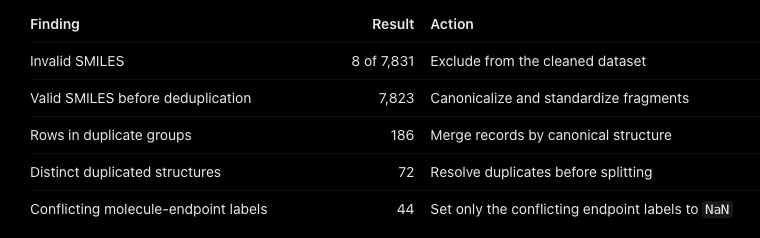

**Clean and deduplicate**

In [26]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold

# Suppress noisy RDKit diagnostic messages.
RDLogger.DisableLog("rdApp.*")

# Output paths in Google Colab.
OUT_DIR = Path("/content/tox21_project")
PROCESSED_DIR = OUT_DIR / "data" / "processed"
SPLITS_DIR = OUT_DIR / "data" / "splits"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

chooser = rdMolStandardize.LargestFragmentChooser()


def canonicalize_smiles(smiles):
    """Parse SMILES, retain the largest fragment, and canonicalize."""
    if not isinstance(smiles, str) or not smiles.strip():
        return None

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    mol = chooser.choose(mol)
    return Chem.MolToSmiles(mol, canonical=True)


def merge_label(series):
    """Keep agreeing observed labels; turn conflicting labels into NaN."""
    values = series.dropna().unique()

    if len(values) == 1:
        return values[0]

    return np.nan


# Start from the untouched raw data.
work = df.copy()
log = {"raw_rows": len(work)}

# 1. Parse, keep largest fragment, canonicalize.
work["smiles_can"] = work["smiles"].map(canonicalize_smiles)

# 2. Drop structures that could not be parsed.
invalid_mask = work["smiles_can"].isna()
log["invalid_dropped"] = int(invalid_mask.sum())

work = work.loc[~invalid_mask].copy()
log["valid_after_parsing"] = len(work)

# 3. Group identical standardized molecular structures.
groups = work.groupby("smiles_can", sort=False)

# Count label conflicts BEFORE merging.
conflict_mask = groups[ENDPOINTS].nunique() > 1
log["label_conflicts_set_to_nan"] = int(conflict_mask.to_numpy().sum())

# Count repeated rows removed by deduplication.
log["duplicate_rows_removed"] = int(
    len(work) - work["smiles_can"].nunique()
)

# 4. Merge each endpoint independently.
clean_df = groups[ENDPOINTS].agg(merge_label).reset_index()

# Retain one representative identifier per structure.
first_ids = groups["mol_id"].first().rename("mol_id")
clean_df.insert(0, "mol_id", first_ids.reindex(
    clean_df["smiles_can"]
).to_numpy())

# Store canonical SMILES in the standard smiles column.
clean_df = clean_df.rename(columns={"smiles_can": "smiles"})

log["clean_rows"] = len(clean_df)

# 5. Generate Bemis-Murcko scaffolds.
clean_df["scaffold"] = clean_df["smiles"].map(
    lambda s: MurckoScaffold.MurckoScaffoldSmiles(
        mol=Chem.MolFromSmiles(s),
        includeChirality=False
    )
)

# Keep column order stable for downstream teammates.
clean_df = clean_df[
    ["mol_id", "smiles", "scaffold", *ENDPOINTS]
]

# 6. Save the cleaned dataset and audit log.
clean_path = PROCESSED_DIR / "tox21_clean.csv"
log_path = PROCESSED_DIR / "dedup_log.txt"

clean_df.to_csv(clean_path, index=False)
log_path.write_text(
    "\n".join(f"{key}: {value}" for key, value in log.items())
)

print("Cleaning complete.")
print(json.dumps(log, indent=2))
print("\nSaved:", clean_path)
print("Saved:", log_path)

Cleaning complete.
{
  "raw_rows": 7831,
  "invalid_dropped": 8,
  "valid_after_parsing": 7823,
  "label_conflicts_set_to_nan": 44,
  "duplicate_rows_removed": 114,
  "clean_rows": 7709
}

Saved: /content/tox21_project/data/processed/tox21_clean.csv
Saved: /content/tox21_project/data/processed/dedup_log.txt


In [27]:
assert clean_df["smiles"].notna().all()
assert clean_df["smiles"].is_unique
assert clean_df["mol_id"].notna().all()
assert clean_df[ENDPOINTS].isin([0, 1]).all().all() or \
       clean_df[ENDPOINTS].isna().any().any()

# Stronger checks: no invalid SMILES and no duplicate canonical structures.
assert all(
    Chem.MolFromSmiles(s) is not None
    for s in clean_df["smiles"]
)

assert clean_df.shape[1] == 15  # ID + SMILES + scaffold + 12 targets

display(clean_df.head())
print("Clean dataset shape:", clean_df.shape)
print("Unique scaffolds:", clean_df["scaffold"].nunique())
print("Acyclic molecules:", (clean_df["scaffold"] == "").sum())
print("Total missing target labels:", clean_df[ENDPOINTS].isna().sum().sum())

,mol_id,smiles,scaffold,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,c1ccc2scnc2c1,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,O=C1NC(=O)C(c2ccccc2)N1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,C1=C2CCC3C4CCCC4CCC3C2CCC1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,c1ccccc1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Clean dataset shape: (7709, 15)
Unique scaffolds: 2285
Acyclic molecules: 1753
Total missing target labels: 15770


In [28]:
from collections import defaultdict


def random_split(n, seed=0, frac=(0.8, 0.1, 0.1)):
    rng = np.random.default_rng(seed)
    permutation = rng.permutation(n)

    train_end = int(frac[0] * n)
    val_end = int((frac[0] + frac[1]) * n)

    return {
        "train": sorted(permutation[:train_end].tolist()),
        "val": sorted(permutation[train_end:val_end].tolist()),
        "test": sorted(permutation[val_end:].tolist())
    }


def scaffold_split(scaffolds, frac=(0.8, 0.1, 0.1)):
    groups = defaultdict(list)

    for i, scaffold in enumerate(scaffolds):
        groups[scaffold].append(i)

    # Larger scaffold families first; deterministic tie-breaking.
    ordered_groups = sorted(
        groups.values(),
        key=lambda group: (len(group), -group[0]),
        reverse=True
    )

    n = len(scaffolds)
    train_cutoff = frac[0] * n
    val_cutoff = (frac[0] + frac[1]) * n

    train, val, test = [], [], []

    for group in ordered_groups:
        if len(train) + len(group) <= train_cutoff:
            train.extend(group)
        elif len(train) + len(val) + len(group) <= val_cutoff:
            val.extend(group)
        else:
            test.extend(group)

    return {
        "train": sorted(train),
        "val": sorted(val),
        "test": sorted(test)
    }


random_indices = random_split(len(clean_df), seed=0)

scaffold_indices = scaffold_split(
    clean_df["scaffold"].fillna("").tolist()
)

for name, split in [
    ("random", random_indices),
    ("scaffold", scaffold_indices)
]:
    output_path = SPLITS_DIR / f"{name}_seed0.json"

    output_path.write_text(json.dumps(split))

    print(f"\n{name.upper()} SPLIT")
    for subset in ["train", "val", "test"]:
        count = len(split[subset])
        print(f"{subset:5s}: {count:5d} ({count / len(clean_df):.1%})")

    print("Saved:", output_path)


RANDOM SPLIT
train:  6167 (80.0%)
val  :   771 (10.0%)
test :   771 (10.0%)
Saved: /content/tox21_project/data/splits/random_seed0.json

SCAFFOLD SPLIT
train:  6167 (80.0%)
val  :   771 (10.0%)
test :   771 (10.0%)
Saved: /content/tox21_project/data/splits/scaffold_seed0.json


In [29]:
def validate_split(split, df, name):
    n = len(df)

    train = set(split["train"])
    val = set(split["val"])
    test = set(split["test"])

    # Every row appears exactly once.
    assert train.isdisjoint(val)
    assert train.isdisjoint(test)
    assert val.isdisjoint(test)

    assert train | val | test == set(range(n))

    print(f"{name}: row partition checks passed.")

    if name == "scaffold":
        scaffold_sets = {
            subset: set(
                df.iloc[split[subset]]["scaffold"].fillna("")
            )
            for subset in ["train", "val", "test"]
        }

        assert scaffold_sets["train"].isdisjoint(scaffold_sets["val"])
        assert scaffold_sets["train"].isdisjoint(scaffold_sets["test"])
        assert scaffold_sets["val"].isdisjoint(scaffold_sets["test"])

        print("Scaffold leakage checks passed.")

        # Confirm where the acyclic group went.
        acyclic_indices = set(
            df.index[df["scaffold"].fillna("") == ""]
        )
        print(
            "Acyclic molecules:",
            len(acyclic_indices),
            "| all in training:",
            acyclic_indices.issubset(train)
        )


validate_split(random_indices, clean_df, "random")
validate_split(scaffold_indices, clean_df, "scaffold")

random: row partition checks passed.
scaffold: row partition checks passed.
Scaffold leakage checks passed.
Acyclic molecules: 1753 | all in training: True


In [30]:
def print_label_coverage(df, split, split_name):
    rows = []

    for subset in ["train", "val", "test"]:
        part = df.iloc[split[subset]]

        for endpoint in ENDPOINTS:
            y = part[endpoint].dropna()

            rows.append({
                "split": subset,
                "endpoint": endpoint,
                "observed": len(y),
                "positive": int((y == 1).sum()),
                "negative": int((y == 0).sum()),
                "missing": int(part[endpoint].isna().sum())
            })

    coverage = pd.DataFrame(rows)

    print(f"\n{split_name.upper()} LABEL COVERAGE")
    display(coverage)

    return coverage


random_coverage = print_label_coverage(
    clean_df, random_indices, "random"
)

scaffold_coverage = print_label_coverage(
    clean_df, scaffold_indices, "scaffold"
)


RANDOM LABEL COVERAGE


,split,endpoint,observed,positive,negative,missing
0,train,NR-AR,5709,238,5471,458
1,train,NR-AR-LBD,5328,180,5148,839
2,train,NR-AhR,5156,618,4538,1011
3,train,NR-Aromatase,4578,229,4349,1589
4,train,NR-ER,4865,625,4240,1302
5,train,NR-ER-LBD,5471,273,5198,696
6,train,NR-PPAR-gamma,5087,143,4944,1080
7,train,SR-ARE,4595,739,3856,1572
8,train,SR-ATAD5,5570,217,5353,597
9,train,SR-HSE,5114,306,4808,1053



SCAFFOLD LABEL COVERAGE


,split,endpoint,observed,positive,negative,missing
0,train,NR-AR,5745,243,5502,422
1,train,NR-AR-LBD,5437,191,5246,730
2,train,NR-AhR,5244,592,4652,923
3,train,NR-Aromatase,4708,192,4516,1459
4,train,NR-ER,5030,642,4388,1137
5,train,NR-ER-LBD,5567,290,5277,600
6,train,NR-PPAR-gamma,5234,133,5101,933
7,train,SR-ARE,4807,687,4120,1360
8,train,SR-ATAD5,5659,197,5462,508
9,train,SR-HSE,5250,271,4979,917


Total molecules: 7709
Unique scaffold groups: 2285
Acyclic molecules: 1753
Acyclic fraction: 0.2274

Top 10 scaffold groups:


,molecule_count
scaffold,
,1753
c1ccccc1,1479
c1ccncc1,88
c1ccc(Cc2ccccc2)cc1,81
c1ccc2ccccc2c1,68
C1CCCCC1,63
c1ccc(Oc2ccccc2)cc1,46
O=C1C=C2CCC3C4CCCC4CCC3C2CC1,43
O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21,41


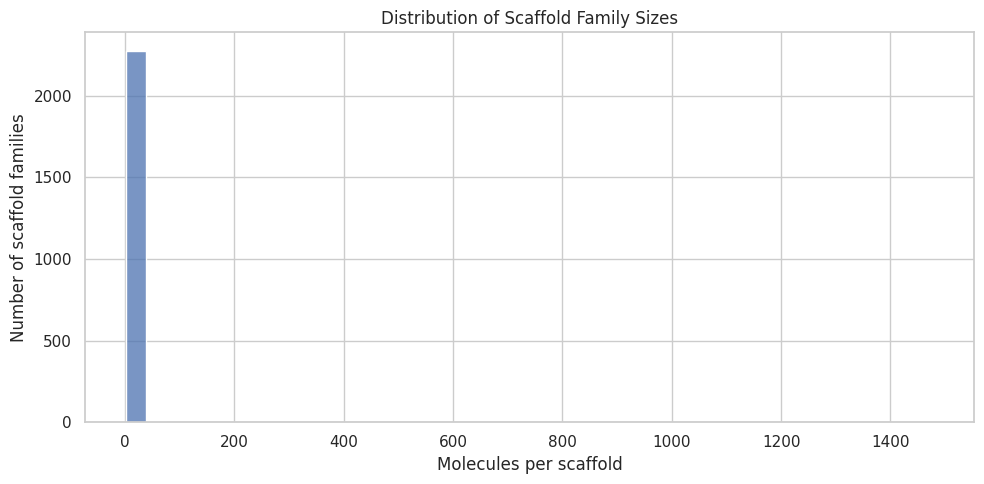

In [31]:
scaffold_sizes = clean_df["scaffold"].fillna("").value_counts()

acyclic_count = int((clean_df["scaffold"].fillna("") == "").sum())

print("Total molecules:", len(clean_df))
print("Unique scaffold groups:", len(scaffold_sizes))
print("Acyclic molecules:", acyclic_count)
print("Acyclic fraction:", round(acyclic_count / len(clean_df), 4))

print("\nTop 10 scaffold groups:")
display(scaffold_sizes.head(10).rename("molecule_count").to_frame())

plt.figure(figsize=(10, 5))
sns.histplot(
    scaffold_sizes[scaffold_sizes.index != ""],
    bins=40
)
plt.title("Distribution of Scaffold Family Sizes")
plt.xlabel("Molecules per scaffold")
plt.ylabel("Number of scaffold families")
plt.tight_layout()
plt.show()

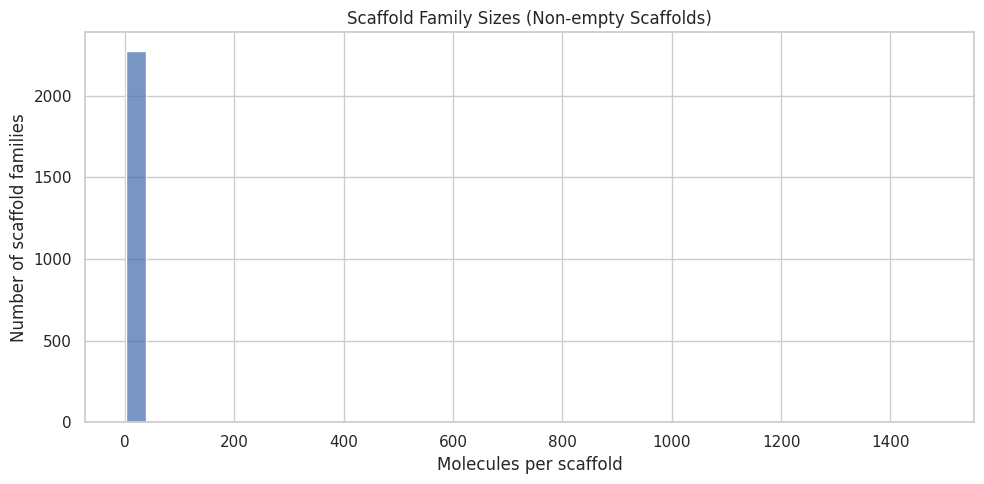

Non-empty scaffold families: 2284
Largest non-empty family: 1479
Singleton scaffold families: 1730


In [32]:
# Count molecules per scaffold, excluding the empty scaffold.
scaffold_series = clean_df["scaffold"].fillna("")

nonempty_scaffolds = scaffold_series[scaffold_series.str.len() > 0]
ringed_scaffold_sizes = nonempty_scaffolds.value_counts()

plt.figure(figsize=(10, 5))
sns.histplot(ringed_scaffold_sizes.values, bins=40)

plt.title("Scaffold Family Sizes (Non-empty Scaffolds)")
plt.xlabel("Molecules per scaffold")
plt.ylabel("Number of scaffold families")
plt.tight_layout()
plt.show()

print("Non-empty scaffold families:", len(ringed_scaffold_sizes))
print("Largest non-empty family:", ringed_scaffold_sizes.max())
print("Singleton scaffold families:", (ringed_scaffold_sizes == 1).sum())

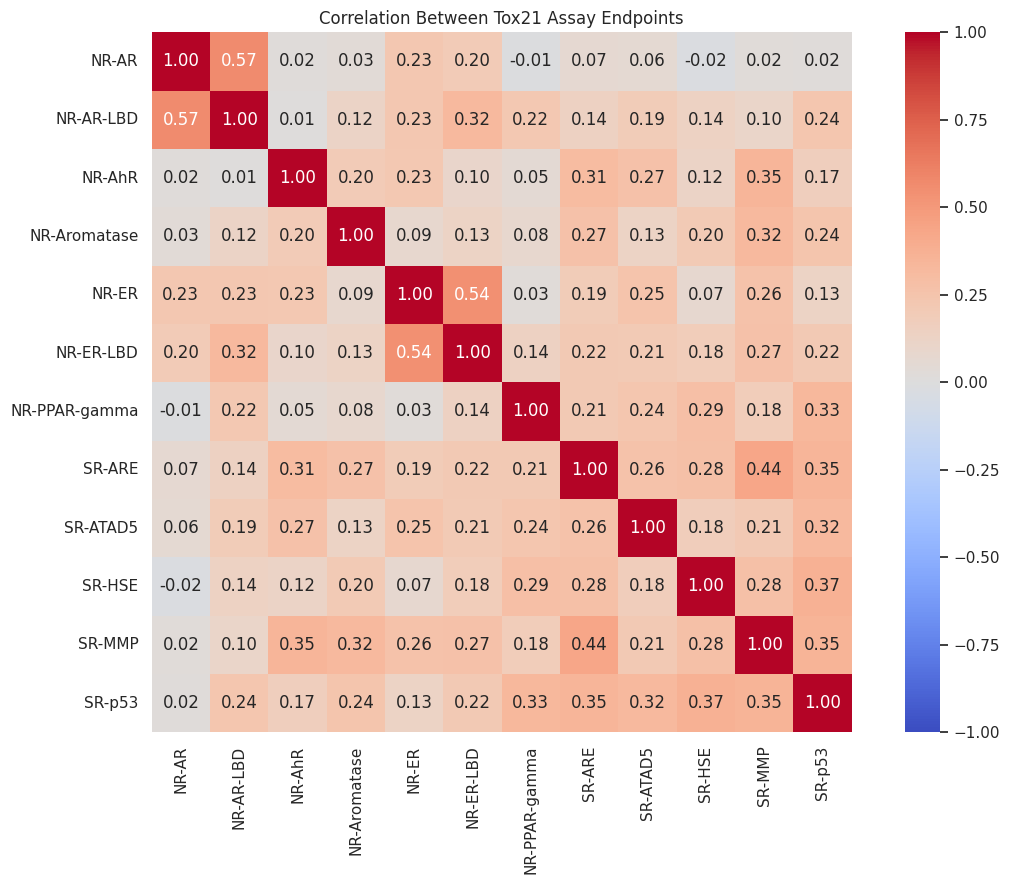

,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
NR-AR,1.000,0.567,0.017,0.033,0.234,0.201,-0.014,0.069,0.056,-0.021,0.024,0.019
NR-AR-LBD,0.567,1.000,0.009,0.121,0.229,0.321,0.223,0.145,0.188,0.140,0.104,0.240
NR-AhR,0.017,0.009,1.000,0.200,0.226,0.098,0.049,0.307,0.273,0.119,0.348,0.171
NR-Aromatase,0.033,0.121,0.200,1.000,0.086,0.126,0.083,0.269,0.132,0.203,0.323,0.244
NR-ER,0.234,0.229,0.226,0.086,1.000,0.543,0.029,0.192,0.255,0.074,0.260,0.130
NR-ER-LBD,0.201,0.321,0.098,0.126,0.543,1.000,0.141,0.216,0.210,0.180,0.269,0.216
NR-PPAR-gamma,-0.014,0.223,0.049,0.083,0.029,0.141,1.000,0.211,0.242,0.286,0.181,0.332
SR-ARE,0.069,0.145,0.307,0.269,0.192,0.216,0.211,1.000,0.260,0.281,0.436,0.350
SR-ATAD5,0.056,0.188,0.273,0.132,0.255,0.210,0.242,0.260,1.000,0.176,0.213,0.322
SR-HSE,-0.021,0.140,0.119,0.203,0.074,0.180,0.286,0.281,0.176,1.000,0.276,0.374


In [33]:
label_corr = clean_df[ENDPOINTS].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    label_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Tox21 Assay Endpoints")
plt.tight_layout()
plt.show()

display(label_corr.round(3))

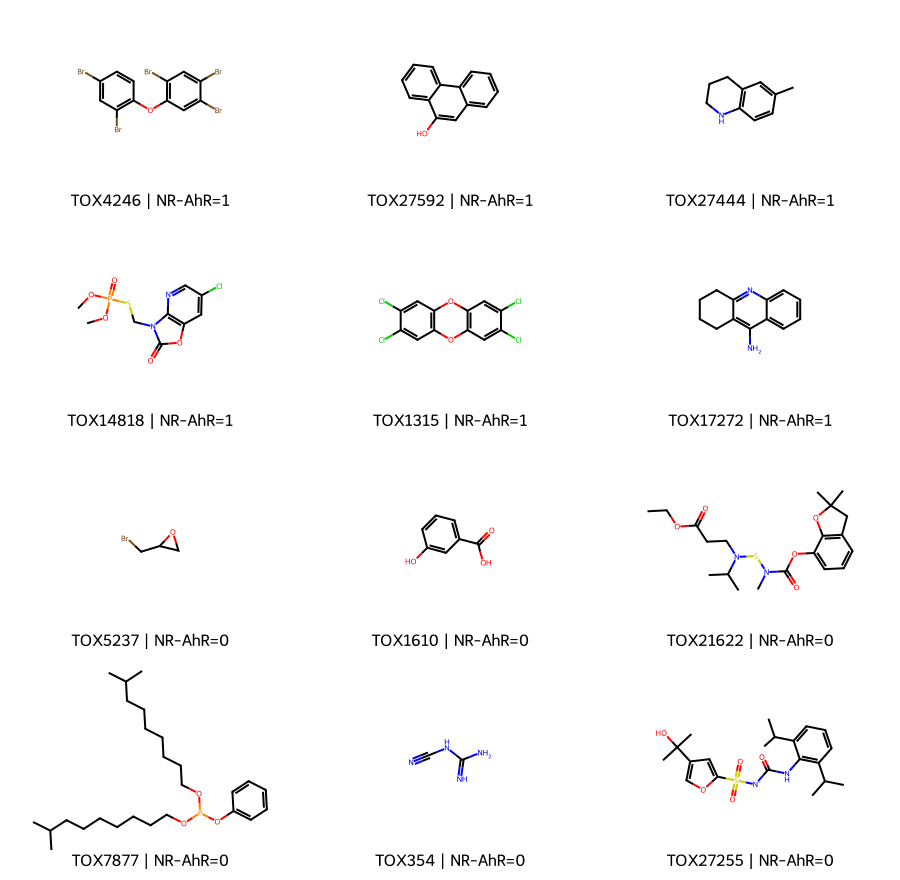

In [34]:
from rdkit.Chem import Draw

endpoint = "NR-AhR"
n_each = 6

positive = clean_df.loc[
    clean_df[endpoint] == 1, ["mol_id", "smiles", endpoint]
].sample(n=n_each, random_state=0)

negative = clean_df.loc[
    clean_df[endpoint] == 0, ["mol_id", "smiles", endpoint]
].sample(n=n_each, random_state=0)

examples = pd.concat([positive, negative], ignore_index=True)

molecules = [Chem.MolFromSmiles(s) for s in examples["smiles"]]

legends = [
    f'{row.mol_id} | {endpoint}={int(row[endpoint])}'
    for _, row in examples.iterrows()
]

grid = Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(300, 220),
    legends=legends,
    useSVG=True
)

display(grid)

In [35]:
from rdkit.Chem import Descriptors, rdFingerprintGenerator

FEATURES_DIR = OUT_DIR / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

# Morgan fingerprints: radius 2, 2048 bits.
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

smiles_list = clean_df["smiles"].tolist()

X_morgan = np.zeros(
    (len(smiles_list), 2048),
    dtype=np.uint8
)

descriptor_rows = []
descriptor_names = None

for i, smiles in enumerate(smiles_list):
    mol = Chem.MolFromSmiles(smiles)

    X_morgan[i] = generator.GetFingerprintAsNumPy(mol)

    descriptors = Descriptors.CalcMolDescriptors(mol)

    if descriptor_names is None:
        descriptor_names = list(descriptors.keys())

    descriptor_rows.append([
        descriptors[name] for name in descriptor_names
    ])

X_desc = np.asarray(descriptor_rows, dtype=np.float64)

# Save arrays in the exact row order of tox21_clean.csv.
np.save(FEATURES_DIR / "morgan_2048.npy", X_morgan)
np.save(FEATURES_DIR / "descriptors_raw.npy", X_desc)

(FEATURES_DIR / "descriptor_names.txt").write_text(
    "\n".join(descriptor_names)
)

print("Morgan fingerprint shape:", X_morgan.shape)
print("Descriptor matrix shape:", X_desc.shape)
print("Descriptor names:", len(descriptor_names))
print("Morgan dtype:", X_morgan.dtype)
print("Descriptor dtype:", X_desc.dtype)

print(
    "Non-finite descriptor values:",
    int((~np.isfinite(X_desc)).sum())
)

Morgan fingerprint shape: (7709, 2048)
Descriptor matrix shape: (7709, 217)
Descriptor names: 217
Morgan dtype: uint8
Descriptor dtype: float64
Non-finite descriptor values: 1230


In [36]:
#some checks before training
# Verify the generated feature matrices
print("Clean rows:", len(clean_df))
print("Morgan shape:", X_morgan.shape)
print("Descriptor shape:", X_desc.shape)

assert X_morgan.shape[0] == len(clean_df)
assert X_desc.shape[0] == len(clean_df)
assert X_morgan.shape[1] == 2048

# Inspect descriptor problems
print("NaN descriptor values:", np.isnan(X_desc).sum())
print("Infinite descriptor values:", np.isinf(X_desc).sum())

# Verify the split files match the cleaned dataset
assert set(random_indices["train"]).isdisjoint(random_indices["test"])
assert set(scaffold_indices["train"]).isdisjoint(scaffold_indices["test"])

Clean rows: 7709
Morgan shape: (7709, 2048)
Descriptor shape: (7709, 217)
NaN descriptor values: 1224
Infinite descriptor values: 6


In [37]:
# Identify problematic descriptor columns
descriptor_names = list(descriptor_names)

descriptor_df = pd.DataFrame(
    X_desc,
    columns=descriptor_names
)

nonfinite_summary = pd.DataFrame({
    "nan_count": descriptor_df.isna().sum(),
    "infinite_count": np.isinf(
        descriptor_df.to_numpy()
    ).sum(axis=0)
})

nonfinite_summary = nonfinite_summary[
    (nonfinite_summary["nan_count"] > 0) |
    (nonfinite_summary["infinite_count"] > 0)
].sort_values(
    ["nan_count", "infinite_count"],
    ascending=False
)

display(nonfinite_summary)

print("Rows with any NaN:",
      np.isnan(X_desc).any(axis=1).sum())

print("Rows with any infinity:",
      np.isinf(X_desc).any(axis=1).sum())

print("Constant descriptor columns:",
      (np.nanstd(X_desc, axis=0) == 0).sum())

,nan_count,infinite_count
BCUT2D_MWHI,107,0
BCUT2D_MWLOW,107,0
BCUT2D_CHGHI,107,0
BCUT2D_CHGLO,107,0
BCUT2D_LOGPHI,107,0
BCUT2D_LOGPLOW,107,0
BCUT2D_MRHI,107,0
BCUT2D_MRLOW,107,0
MaxPartialCharge,92,2
MaxAbsPartialCharge,92,2


Rows with any NaN: 107
Rows with any infinity: 2
Constant descriptor columns: 3


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1899: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)


In [38]:
# Identify rows with non-finite descriptor values
finite_mask = np.isfinite(X_desc)

bad_rows = np.where(~finite_mask.all(axis=1))[0]

print("Rows with non-finite values:", len(bad_rows))

bad_molecules = clean_df.iloc[bad_rows][
    ["mol_id", "smiles"]
].copy()

display(bad_molecules)

# Summarize all non-finite descriptor cells
bad_cells = []

for j, name in enumerate(descriptor_names):
    col = X_desc[:, j]

    nan_count = np.isnan(col).sum()
    inf_count = np.isinf(col).sum()

    if nan_count or inf_count:
        bad_cells.append({
            "descriptor": name,
            "NaN": int(nan_count),
            "infinity": int(inf_count)
        })

display(pd.DataFrame(bad_cells))

# Find constant columns using finite values only
constant_features = []

for j, name in enumerate(descriptor_names):
    finite_values = X_desc[np.isfinite(X_desc[:, j]), j]

    if len(finite_values) > 0 and np.unique(finite_values).size == 1:
        constant_features.append(name)

print("Constant descriptors:", constant_features)

Rows with non-finite values: 107


,mol_id,smiles
69,TOX956,O=[N+]([O-])c1cc([As](=O)(O)O)ccc1O
145,TOX25007,O=[N+]([O-])c1ccc([As](=O)(O)O)cc1
149,TOX21803,[Cu][I]
252,TOX813,[CH3][Hg][Cl]
254,TOX811,[Hg+2]
...,...,...
7240,TOX26308,OB(O)[O][Hg][c]1ccccc1
7291,TOX21126,N#[C][Fe-2]([C]#N)([C]#N)([C]#N)([C]#N)[N]=O
7375,TOX9679,[Cl][Sn]([Cl])([Cl])[Cl]
7441,TOX508,C[As](C)(=O)O


,descriptor,NaN,infinity
0,MaxPartialCharge,92,2
1,MinPartialCharge,92,1
2,MaxAbsPartialCharge,92,2
3,MinAbsPartialCharge,92,1
4,BCUT2D_MWHI,107,0
5,BCUT2D_MWLOW,107,0
6,BCUT2D_CHGHI,107,0
7,BCUT2D_CHGLO,107,0
8,BCUT2D_LOGPHI,107,0
9,BCUT2D_LOGPLOW,107,0


Constant descriptors: ['SMR_VSA8', 'SlogP_VSA9', 'fr_diazo']


In [39]:
constant_check = []

for name in constant_features:
    j = descriptor_names.index(name)
    values = X_desc[:, j]
    finite = values[np.isfinite(values)]

    constant_check.append({
        "descriptor": name,
        "finite_unique_values": np.unique(finite).size,
        "finite_value": finite[0] if len(finite) else np.nan,
        "nan_count": int(np.isnan(values).sum()),
        "infinite_count": int(np.isinf(values).sum())
    })

display(pd.DataFrame(constant_check))

,descriptor,finite_unique_values,finite_value,nan_count,infinite_count
0,SMR_VSA8,1,0.0,0,0
1,SlogP_VSA9,1,0.0,0,0
2,fr_diazo,1,0.0,0,0


### Molecular Descriptor Quality

The dataset contains 7,709 standardized molecular structures represented by 217 RDKit descriptors. A total of 107 molecules have at least one non-finite descriptor value (1.39% of the dataset). Eight BCUT2D descriptors each contain 107 missing values, while four partial-charge descriptors contain 92 missing values each and exhibit a small number of infinite values.

The affected molecules include structures containing unusual elements such as arsenic, mercury, copper, iron, and tin. These findings indicate descriptor-calculation limitations for some structures, rather than necessarily invalid molecular representations.

Three descriptors, `SMR_VSA8`, `SlogP_VSA9`, and `fr_diazo`, have been identified as constant among their finite values. These findings will inform later feature preprocessing. The raw descriptor matrix is preserved without imputation, scaling, or feature deletion during EDA.

In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

OUT_DIR = Path("/content/tox21_project")

saved_df = pd.read_csv(
    OUT_DIR / "data/processed/tox21_clean.csv"
)

saved_morgan = np.load(
    OUT_DIR / "features/morgan_2048.npy"
)

saved_desc = np.load(
    OUT_DIR / "features/descriptors_raw.npy"
)

with open(
    OUT_DIR / "data/splits/random_seed0.json"
) as f:
    random_split_saved = json.load(f)

with open(
    OUT_DIR / "data/splits/scaffold_seed0.json"
) as f:
    scaffold_split_saved = json.load(f)

assert saved_df.shape == (7709, 15)
assert saved_morgan.shape == (7709, 2048)
assert saved_desc.shape == (7709, 217)

for split in [random_split_saved, scaffold_split_saved]:
    all_indices = (
        split["train"] + split["val"] + split["test"]
    )
    assert sorted(all_indices) == list(range(len(saved_df)))

print("All saved artifact shapes and split indices are valid.")

All saved artifact shapes and split indices are valid.
